# HW1 – Introduction and Learnability : PAC vs PAC agnostique

**Objectif.** Illustrer expérimentalement la différence entre l'apprentissage PAC (cas réalisable) et PAC agnostique (cas bruité), avec un algorithme ERM écrit à la main pour la classe des seuils sur $\mathcal{X}=[0,1]$.

**Sommaire** : 1. Génération des données · 2. ERM · 3. Erreur empirique vs erreur vraie · 4. Vérification expérimentale du PAC · 5. Passage à l'agnostique · 6. Conclusion

**Choix des paramètres (justifiés)** :
- $\theta = 0.35$ : seuil non centré, pour éviter un cas symétrique trivial ;
- $\varepsilon = 0.05$ : précision visée (5 % d'erreur en excès) ;
- $\delta = 0.05$ : confiance visée (95 %) ;
- $\eta = 0.15$ : bruit modéré (plus tard on fait varier $\eta$) ;
- $m \in \{5,10,20,50,100,200\}$, **1000 répétitions** par $m$ ;
- test set de $2\times 10^5$ points (erreur de test précise à ~$10^{-3}$).

**Notations** : $S$ échantillon, $L_S(h)$ erreur empirique, $\text{ERM}_{\mathcal H}(S)\in\arg\min_{h\in\mathcal H}L_S(h)$, $h_S$ hypothèse retournée. Dans le notebook, `L(h)` désigne l'erreur réelle : $L_{\mathcal D,f}(h)=\Pr_{x\sim\mathcal D}[h(x)\neq f(x)]$ en cadre réalisable, et $L_{\mathcal D}(h)=\Pr_{(x,y)\sim\mathcal D}[h(x)\neq y]$ en cadre agnostique. Ici $\mathcal D$ = uniforme sur $[0,1]$ (plus bruit d'étiquette dans le cas agnostique).

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(42)

THETA = 0.35
EPS, DELTA = 0.05, 0.05
ETA = 0.15
M_LIST = [5, 10, 20, 50, 100, 200]
N_REPS = 1000
N_TEST = 200_000

## 1. Génération des données
Les $x_i$ sont tirés uniformément dans $[0,1]$. Dans le cas réalisable $y=f_\theta(x)=\mathbb 1[x>\theta]$ ; dans le cas agnostique, chaque label est inversé indépendamment avec probabilité $\eta$.

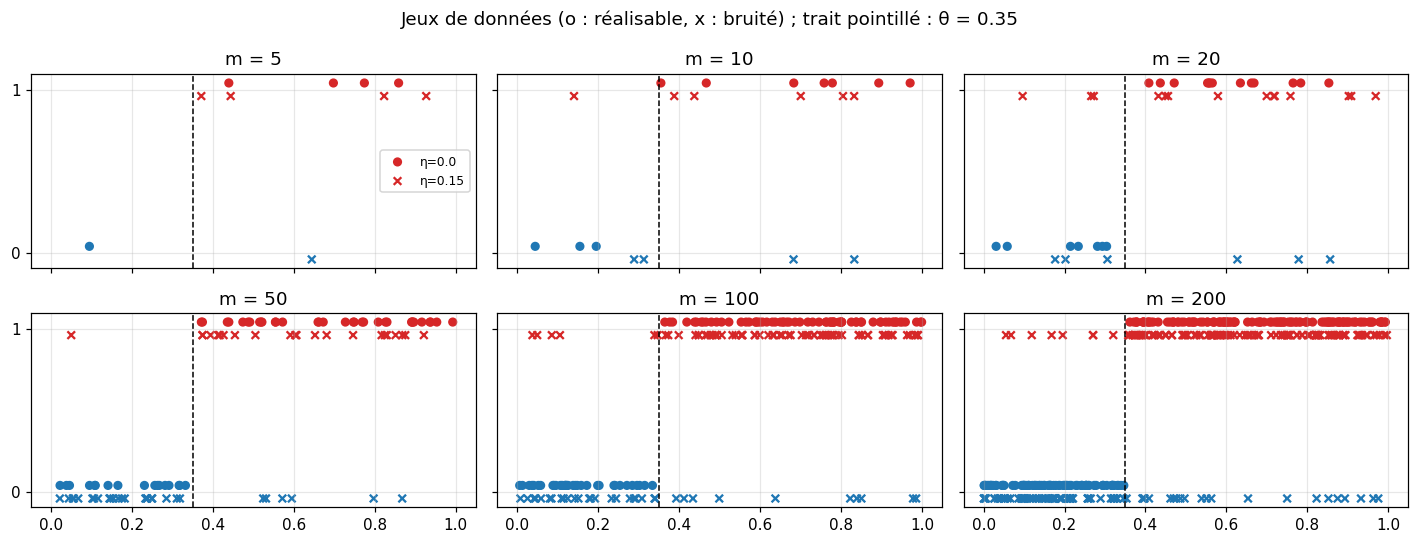

In [11]:
def f_theta(x, theta=THETA):
    return (x > theta).astype(int)

def generate_data(m, theta=THETA, eta=0.0, rng=rng):
    """m points uniformes ; labels = f_theta, inversés avec proba eta."""
    x = rng.uniform(0, 1, size=m)
    y = f_theta(x, theta)
    flip = rng.random(m) < eta
    return x, np.where(flip, 1 - y, y)

fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex=True, sharey=True)
for ax, m in zip(axes.ravel(), M_LIST):
    for eta, off, mk in [(0.0, 0.04, "o"), (ETA, -0.04, "x")]:
        x, y = generate_data(m, eta=eta)
        ax.scatter(x, y + off, c=np.where(y == 1, "tab:red", "tab:blue"), marker=mk, s=25,
                   label=f"η={eta}")
    ax.axvline(THETA, color="k", ls="--", lw=1)
    ax.set_title(f"m = {m}"); ax.set_yticks([0, 1])
axes[0, 0].legend(loc="center right", fontsize=8)
fig.suptitle(f"Jeux de données (o : réalisable, x : bruité) ; trait pointillé : θ = {THETA}")
plt.tight_layout(); plt.show()

Dans le cas réalisable (ronds), tous les points à gauche de $\theta$ ont le label 0 et tous ceux à droite le label 1 : un seuil parfait existe. Avec bruit (croix), quelques points « aberrants » apparaissent de l'autre côté de $\theta$ : aucun seuil ne peut tous les classer correctement.

## 2. Implémentation de l'ERM
**Classe d'hypothèses** : $\mathcal H=\{h_t(x)=\mathbb 1[x>t],\ t\in[0,1]\}$.

**Stratégie.** L'erreur empirique de $h_t$ ne change que lorsque $t$ traverse un point d'entraînement. Il suffit donc de tester les $m+1$ positions possibles (avant le 1er point, entre deux points consécutifs, après le dernier). Après tri des points, si $k$ points sont à gauche de $t$ :
$$\hat L(h_t)=\frac1m\Big(\underbrace{\#\{y_i=1\text{ parmi les }k\text{ premiers}\}}_{\text{prédits 0 à tort}}+\underbrace{\#\{y_i=0\text{ parmi les }m-k\text{ derniers}\}}_{\text{prédits 1 à tort}}\Big)$$
calculable pour tous les $k$ en $O(m)$ avec des sommes cumulées (complexité totale $O(m\log m)$ à cause du tri). On prend le $k$ minimisant l'erreur et on place le seuil au **milieu** de l'intervalle correspondant (choix de départage en cas d'égalité : premier minimiseur).

In [12]:
def erm_threshold(x, y):
    """ERM pour les seuils. Retourne (t_hat, erreur empirique)."""
    order = np.argsort(x)
    xs, ys = x[order], y[order]
    m = len(xs)
    ones_prefix = np.concatenate([[0], np.cumsum(ys)])          # #1 parmi les k premiers
    zeros_suffix = (m - ones_prefix[-1]) - (np.arange(m + 1) - ones_prefix)  # #0 parmi les m-k derniers
    errors = ones_prefix + zeros_suffix                          # nb d'erreurs pour chaque k
    k = int(np.argmin(errors))
    edges = np.concatenate([[0.0], xs, [1.0]])
    t_hat = 0.5 * (edges[k] + edges[k + 1])
    return t_hat, errors[k] / m

# test rapide : sur données réalisables, l'erreur empirique doit être 0
x, y = generate_data(50)
t, e = erm_threshold(x, y); print(f"θ̂ = {t:.3f} (θ = {THETA}), erreur empirique = {e}")

θ̂ = 0.353 (θ = 0.35), erreur empirique = 0.0


## 3. Évaluation : erreur empirique vs erreur vraie
L'erreur vraie $L_{\mathcal D}(h)$ est estimée sur un grand jeu de test indépendant (généré une seule fois, et trié pour évaluer l'erreur de n'importe quel seuil en $O(\log n)$). Dans le cas agnostique, le jeu de test est lui aussi bruité (c'est la distribution $\mathcal D$ sur laquelle on mesure le risque) : le meilleur risque atteignable est alors $L^*=\eta$.

In [13]:
class TestSet:
    def __init__(self, n=N_TEST, theta=THETA, eta=0.0, rng=rng):
        x, y = generate_data(n, theta, eta, rng)
        o = np.argsort(x)
        self.x, self.y, self.n = x[o], y[o], n
        self.cum1 = np.concatenate([[0], np.cumsum(self.y)])
    def error(self, t):
        k = np.searchsorted(self.x, t, side="right")             # points avec x <= t (prédits 0)
        ones_left = self.cum1[k]
        zeros_right = (self.n - self.cum1[-1]) - (k - ones_left)
        return (ones_left + zeros_right) / self.n

test_real = TestSet(eta=0.0)
test_noisy = TestSet(eta=ETA)

def run_one(m, eta, test):
    x, y = generate_data(m, eta=eta)
    t, emp = erm_threshold(x, y)
    return t, emp, test.error(t)

import pandas as pd
rows = []
for m in M_LIST:
    for name, eta, ts in [("réalisable", 0.0, test_real), (f"agnostique η={ETA}", ETA, test_noisy)]:
        t, emp, tru = run_one(m, eta, ts)
        rows.append(dict(m=m, cadre=name, theta_hat=round(t, 3), err_empirique=round(emp, 3), err_vraie=round(tru, 3)))
pd.DataFrame(rows).pivot(index="m", columns="cadre", values=["theta_hat", "err_empirique", "err_vraie"])

theta_hat                err_empirique             \
cadre agnostique η=0.15 réalisable agnostique η=0.15 réalisable   
m                                                                 
5                 0.528      0.187             0.000        0.0   
10                0.647      0.302             0.200        0.0   
20                0.009      0.371             0.250        0.0   
50                0.324      0.365             0.200        0.0   
100               0.348      0.348             0.130        0.0   
200               0.349      0.350             0.175        0.0   

              err_vraie             
cadre agnostique η=0.15 réalisable  
m                                   
5                 0.274      0.163  
10                0.358      0.047  
20                0.389      0.021  
50                0.168      0.015  
100               0.151      0.003  
200               0.150      0.000

**Commentaire.** Ce tableau correspond à *une seule* réalisation par couple $(m,\text{cadre})$, donc il est bruité. On y voit déjà que dans le cas réalisable l'erreur empirique vaut 0 pour tout $m$ alors que l'erreur vraie est strictement positive (surtout pour petit $m$) : l'erreur empirique sous-estime l'erreur vraie. Dans le cas bruité, l'erreur vraie reste proche de (ou au-dessus de) $\eta$. La suite moyenne sur de nombreuses répétitions.

## 4. Vérification expérimentale du PAC (cas réalisable)
Pour chaque $m$, on répète 1000 fois (nouveau jeu d'entraînement à chaque fois) et on estime $\Pr\big(L(h)>\varepsilon\big)$ par la fréquence empirique. On trace aussi un intervalle de confiance à 95 % (binomial) et la référence $e^{-\varepsilon m}$.

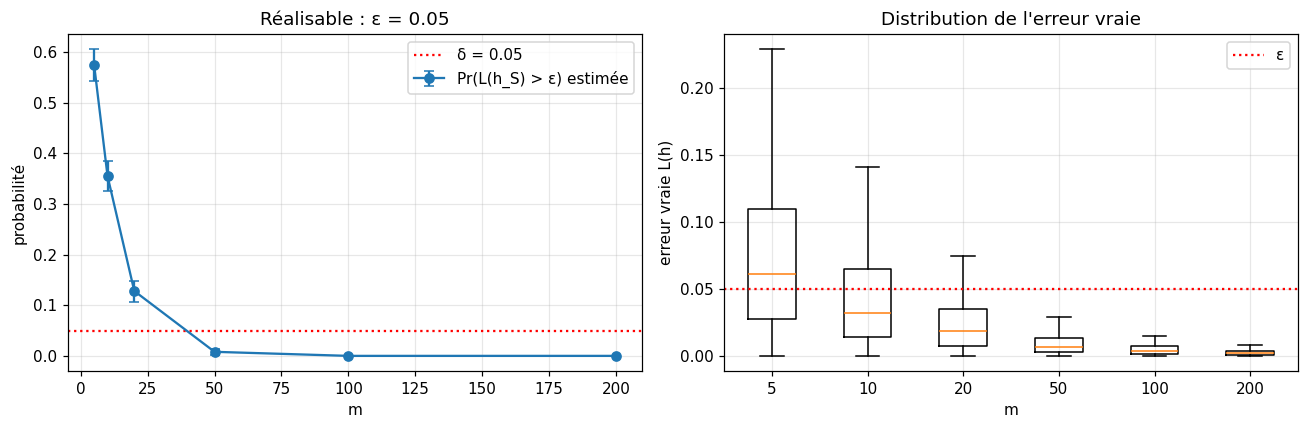

  m  Pr(L>ε)  err vraie moyenne  err empirique moyenne
  5    0.574             0.0741                    0.0
 10    0.355             0.0440                    0.0
 20    0.128             0.0247                    0.0
 50    0.008             0.0097                    0.0
100    0.000             0.0048                    0.0
200    0.000             0.0026                    0.0

Plus petit m testé avec Pr(L>ε) ≤ δ : 50


In [14]:
def experiment(m_list, eta, test, reps=N_REPS):
    out = {}
    for m in m_list:
        res = np.array([run_one(m, eta, test)[1:] for _ in range(reps)])
        out[m] = dict(emp=res[:, 0], true=res[:, 1])
    return out

res_real = experiment(M_LIST, 0.0, test_real)

def prob_curve(res, level):
    p = np.array([(res[m]["true"] > level).mean() for m in M_LIST])
    ci = 1.96 * np.sqrt(p * (1 - p) / N_REPS)
    return p, ci

p_real, ci_real = prob_curve(res_real, EPS)
ms = np.array(M_LIST)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].errorbar(ms, p_real, yerr=ci_real, fmt="o-", capsize=3, label="Pr(L(h_S) > ε) estimée")
ax[0].axhline(DELTA, color="r", ls=":", label=f"δ = {DELTA}")
ax[0].set_xlabel("m"); ax[0].set_ylabel("probabilité"); ax[0].set_title(f"Réalisable : ε = {EPS}"); ax[0].legend()
ax[1].boxplot([res_real[m]["true"] for m in M_LIST], tick_labels=M_LIST, showfliers=False)
ax[1].axhline(EPS, color="r", ls=":", label="ε"); ax[1].set_xlabel("m"); ax[1].set_ylabel("erreur vraie L(h)")
ax[1].set_title("Distribution de l'erreur vraie"); ax[1].legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({"m": M_LIST, "Pr(L>ε)": p_real.round(3), "err vraie moyenne": [res_real[m]["true"].mean().round(4) for m in M_LIST],
                    "err empirique moyenne": [res_real[m]["emp"].mean().round(4) for m in M_LIST]}).to_string(index=False))
m_needed = next((m for m, p in zip(M_LIST, p_real) if p <= DELTA), None)
print(f"\nPlus petit m testé avec Pr(L>ε) ≤ δ : {m_needed}")


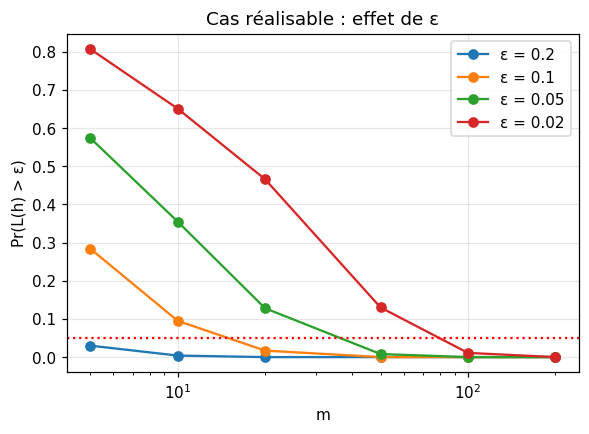

In [15]:
# Sensibilité à ε : courbes Pr(L(h) > ε) pour plusieurs ε
plt.figure(figsize=(6, 4))
for e in [0.2, 0.1, 0.05, 0.02]:
    p, _ = prob_curve(res_real, e); plt.plot(ms, p, "o-", label=f"ε = {e}")
plt.axhline(DELTA, color="r", ls=":"); plt.xscale("log"); plt.xlabel("m"); plt.ylabel("Pr(L(h) > ε)")
plt.title("Cas réalisable : effet de ε"); plt.legend(); plt.show()

**Interprétation.** Pr$(L_{\mathcal D,f}(h_S)>\varepsilon)$ décroît **rapidement** avec $m$ et tend vers 0 : pour $\varepsilon$ et $\delta$ donnés, il existe un $m$ à partir duquel cette probabilité passe sous $\delta$ , c'est exactement la propriété PAC : $\Pr(L_{\mathcal D,f}(h)\le\varepsilon)\ge1-\delta$ dès que $m\ge m_{\mathcal H}(\varepsilon,\delta)$. Plus $\varepsilon$ est petit, plus il faut d'exemples. L'erreur empirique $L_S(h_S)$ est toujours nulle (conséquence de la réalisabilité : l'ERM renvoie une hypothèse cohérente avec $S$).

⚠️ **Limite** : la classe de *tous* les seuils de $[0,1]$ est infinie, or la borne classique $m\ge\log(|\mathcal H|/\delta)/\varepsilon$ suppose $|\mathcal H|<\infty$. On la vérifie donc ci-dessous sur une version **discrétisée** (finie) de la classe.

## 4 bis. Classe finie : vérification de la borne théorique
Si $|\mathcal H|<\infty$, réalisabilité et i.i.d., alors, pour tout $\varepsilon,\delta\in(0,1)$, $\Pr\big(L_{\mathcal D,f}(h_S)>\varepsilon\big)<|\mathcal H|\,e^{-\varepsilon m}$, donc $m\ge \frac{\log(|\mathcal H|/\delta)}{\varepsilon}$ suffit pour une confiance $1-\delta$.

On se place sur $\mathcal H_K=\{h_t:\ t\in\{0,\tfrac1K,\dots,\tfrac{K-1}{K}\}\}$ avec $K=20$ ($|\mathcal H_K|=20$). Comme $\theta=0.35=7/20$ est sur la grille, $f_\theta\in\mathcal H_K$ : la réalisabilité tient. On compare la fréquence observée de $\{L(h_S)>\varepsilon\}$ à la borne $\min(1,|\mathcal H|e^{-\varepsilon m})$.

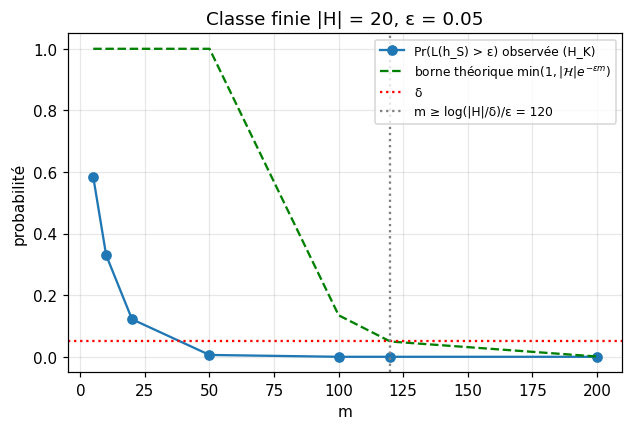

  m  observée  borne
  5     0.584  1.000
 10     0.330  1.000
 20     0.122  1.000
 50     0.006  1.000
100     0.000  0.135
120     0.000  0.050
200     0.000  0.001
Borne théorique : m ≥ 120 garantit Pr(L>ε) ≤ δ ; premier m testé avec fréquence observée ≤ δ : 50


In [16]:

K = 20
GRID = np.arange(K) / K                       # H_K : seuils t_j = j/K  (|H_K| = K)

def erm_finite(x, y, grid=GRID):
    """ERM sur une classe finie : on évalue L_S(h_t) pour chaque t de la grille (premier minimiseur)."""
    preds = (x[:, None] > grid[None, :]).astype(int)       # m x K
    errs = (preds != y[:, None]).mean(axis=0)
    j = int(np.argmin(errs))
    return grid[j], errs[j]

M_FINITE = [5, 10, 20, 50, 100, 120, 200]
p_fin = []
for m in M_FINITE:
    fails = 0
    for _ in range(N_REPS):
        x, y = generate_data(m)
        t, emp = erm_finite(x, y)
        fails += test_real.error(t) > EPS
    p_fin.append(fails / N_REPS)
p_fin = np.array(p_fin); ms_f = np.array(M_FINITE)
bound = np.minimum(1, K * np.exp(-EPS * ms_f))
m_th = int(np.ceil(np.log(K / DELTA) / EPS))

plt.figure(figsize=(6.5, 4))
plt.plot(ms_f, p_fin, "o-", label="Pr(L(h_S) > ε) observée (H_K)")
plt.plot(ms_f, bound, "g--", label=r"borne théorique $\min(1,|\mathcal{H}|e^{-\varepsilon m})$")
plt.axhline(DELTA, color="r", ls=":", label="δ"); plt.axvline(m_th, color="gray", ls=":", label=f"m ≥ log(|H|/δ)/ε = {m_th}")
plt.xlabel("m"); plt.ylabel("probabilité"); plt.title(f"Classe finie |H| = {K}, ε = {EPS}"); plt.legend(fontsize=8); plt.show()
print(pd.DataFrame({"m": M_FINITE, "observée": p_fin.round(3), "borne": bound.round(3)}).to_string(index=False))
print(f"Borne théorique : m ≥ {m_th} garantit Pr(L>ε) ≤ δ ; premier m testé avec fréquence observée ≤ δ : "
      f"{next((m for m, p in zip(M_FINITE, p_fin) if p <= DELTA), None)}")


**Interprétation.** La fréquence observée reste **en dessous de la borne** théorique pour tout $m$ (la borne est valide) mais elle est **conservatrice** : l'union bound sur $|\mathcal H|$ hypothèses et l'inégalité $1-\varepsilon\le e^{-\varepsilon m}$ surestiment la probabilité d'échec, donc le $m$ garanti par le théorème est plus grand que celui réellement nécessaire. Le théorème donne une garantie **de pire cas**, valable pour toute $\mathcal D$ et toute $f\in\mathcal H$ ; nos expériences n'en testent qu'une ($\mathcal D$ uniforme, $\theta=0.35$).

## 5. Du PAC au PAC agnostique
On ajoute un bruit d'étiquette $\eta$ : $\mathcal D$ devient une loi sur $\mathcal X\times\mathcal Y$ (le labeling n'est plus déterministe). Pour $\eta<1/2$, le **prédicteur de Bayes** est $f_\theta$ lui-même et l'**erreur de Bayes** vaut $\eta$ ; comme $h_\theta\in\mathcal H$, on a $\min_{h'\in\mathcal H}L_{\mathcal D}(h')=\eta$. La garantie agnostique PAC s'écrit :
$$\Pr_{S\sim\mathcal D^m}\Big(L_{\mathcal D}(h_S)\le \min_{h'\in\mathcal H}L_{\mathcal D}(h')+\varepsilon\Big)\ge 1-\delta,$$
donc on estime $\Pr\big(L_{\mathcal D}(h_S)-\eta>\varepsilon\big)$.

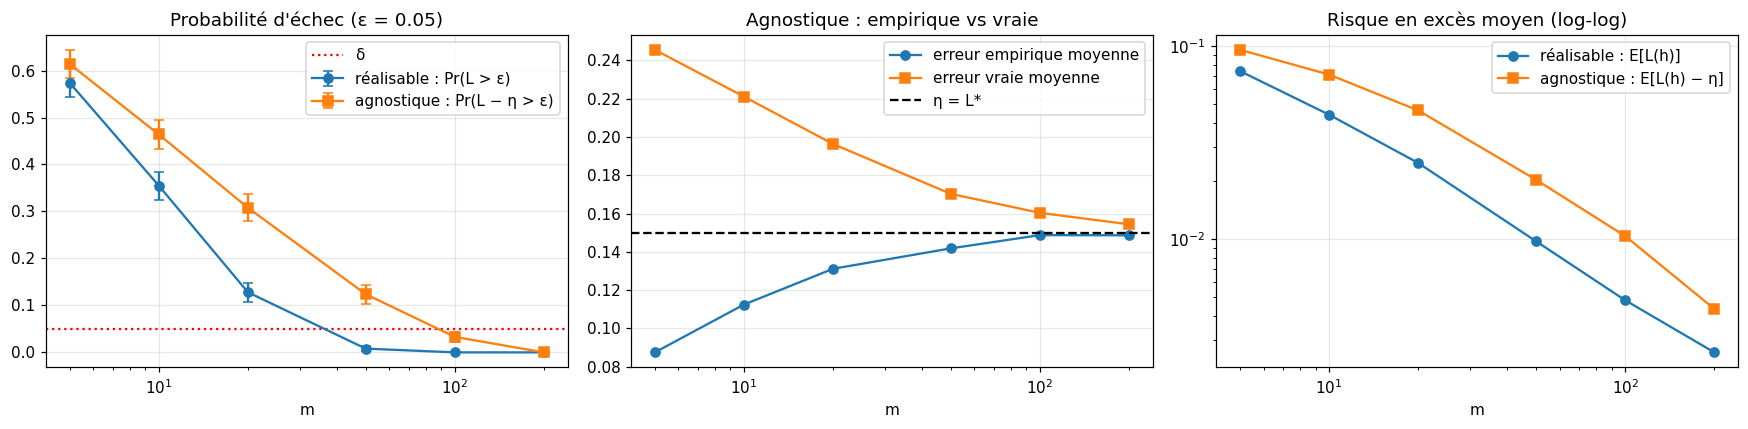

  m  Pr(L>ε) réal.  Pr(L−η>ε) agn.  emp moy (agn.)  vraie moy (agn.)  P(emp = 0)
  5          0.574           0.614           0.087             0.246       0.608
 10          0.355           0.464           0.112             0.221       0.285
 20          0.128           0.308           0.131             0.196       0.056
 50          0.008           0.124           0.142             0.170       0.000
100          0.000           0.033           0.149             0.160       0.000
200          0.000           0.000           0.149             0.154       0.000

Pente log-log du risque en excès : réalisable ≈ -0.93, agnostique ≈ -0.84


In [17]:
res_noisy = experiment(M_LIST, ETA, test_noisy)
exc = {m: res_noisy[m]["true"] - ETA for m in M_LIST}      # risque en excès par rapport à L* = η

p_ag = np.array([(exc[m] > EPS).mean() for m in M_LIST])
ci_ag = 1.96 * np.sqrt(p_ag * (1 - p_ag) / N_REPS)
zero_frac = [(res_noisy[m]["emp"] == 0).mean() for m in M_LIST]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].errorbar(ms, p_real, yerr=ci_real, fmt="o-", capsize=3, label="réalisable : Pr(L > ε)")
ax[0].errorbar(ms, p_ag, yerr=ci_ag, fmt="s-", capsize=3, label=f"agnostique : Pr(L − η > ε)")
ax[0].axhline(DELTA, color="r", ls=":", label="δ"); ax[0].set_xscale("log"); ax[0].set_xlabel("m")
ax[0].set_title(f"Probabilité d'échec (ε = {EPS})"); ax[0].legend()
ax[1].plot(ms, [res_noisy[m]["emp"].mean() for m in M_LIST], "o-", label="erreur empirique moyenne")
ax[1].plot(ms, [res_noisy[m]["true"].mean() for m in M_LIST], "s-", label="erreur vraie moyenne")
ax[1].axhline(ETA, color="k", ls="--", label="η = L*"); ax[1].set_xscale("log"); ax[1].set_xlabel("m")
ax[1].set_title("Agnostique : empirique vs vraie"); ax[1].legend()
ax[2].plot(ms, [res_real[m]["true"].mean() for m in M_LIST], "o-", label="réalisable : E[L(h)]")
ax[2].plot(ms, [exc[m].mean() for m in M_LIST], "s-", label="agnostique : E[L(h) − η]")
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlabel("m"); ax[2].set_title("Risque en excès moyen (log-log)"); ax[2].legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({"m": M_LIST, "Pr(L>ε) réal.": p_real.round(3), "Pr(L−η>ε) agn.": p_ag.round(3),
                    "emp moy (agn.)": [res_noisy[m]["emp"].mean().round(3) for m in M_LIST],
                    "vraie moy (agn.)": [res_noisy[m]["true"].mean().round(3) for m in M_LIST],
                    "P(emp = 0)": np.round(zero_frac, 3)}).to_string(index=False))
slope = lambda d: np.polyfit(np.log(ms), np.log([d[m].mean() for m in M_LIST]), 1)[0]
print(f"\nPente log-log du risque en excès : réalisable ≈ {slope({m: res_real[m]['true'] for m in M_LIST}):.2f}, agnostique ≈ {slope(exc):.2f}")

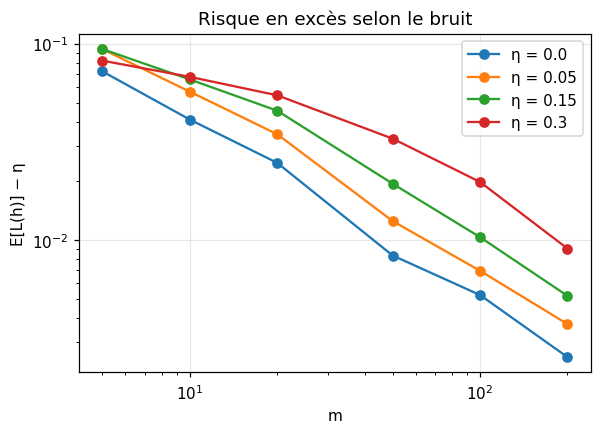

In [18]:
# Effet du niveau de bruit η sur le risque en excès
plt.figure(figsize=(6, 4))
for eta in [0.0, 0.05, 0.15, 0.30]:
    ts = TestSet(eta=eta); r = experiment(M_LIST, eta, ts, reps=300)
    plt.plot(ms, [(r[m]["true"] - eta).mean() for m in M_LIST], "o-", label=f"η = {eta}")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("m"); plt.ylabel("E[L(h)] − η")
plt.title("Risque en excès selon le bruit"); plt.legend(); plt.show()

**Réponses aux questions.**

- **L'erreur empirique peut-elle encore atteindre zéro ?** Non en pratique : dès qu'au moins un label est inversé du « mauvais » côté de $\theta$, aucun seuil ne classe tout correctement. La fréquence de $\hat L=0$ (colonne `P(emp = 0)`) n'est non négligeable que pour très petit $m$ (où il est fréquent qu'aucun label ne soit inversé, ou que les inversions restent compatibles avec un seuil) et s'effondre ensuite. L'erreur empirique moyenne est nettement sous $\eta$ pour petit $m$ (l'ERM « sur-apprend » le bruit : biais optimiste) puis converge vers $\eta\approx0.15$ ; l'écart avec l'erreur vraie se referme quand $m$ augmente.
- **Augmenter $m$ améliore-t-il encore la généralisation ?** Oui, mais **le plafond est $L^*=\eta$**, pas 0 : l'erreur vraie ne descend jamais sous $\eta$, et c'est le risque *en excès* $L(h)-\eta$ qui tend vers 0. Il décroît **moins vite en pratique** que dans le cas réalisable : à $m$ donné il est plus grand, et $\Pr(L(h)-\eta>\varepsilon)$ passe sous $\delta$ pour $m\approx 100$ contre $m\approx 50$ dans le cas réalisable (cf. tableau ; les pentes log-log sont proches, ≈ −0,9, car ce problème 1D est « facile » ; la borne théorique en $1/\varepsilon^2$ est un pire cas), et d'autant plus lentement que $\eta$ est proche de $1/2$. Il faut donc nettement plus d'exemples pour atteindre la même précision $\varepsilon$ avec la même confiance.
- **Lien avec la théorie PAC.** *Réalisable* : l'ERM garantit $L_{\mathcal D,f}(h_S)\le\varepsilon$ avec proba $\ge1-\delta$ ; pour une classe finie, $m\ge\log(|\mathcal H|/\delta)/\varepsilon$ suffit (vérifié sur la classe discrétisée). *Agnostique* : on ne peut plus viser $L=0$, car le meilleur risque de la classe est $\min_{h'}L_{\mathcal D}(h')=\eta$ ; la garantie devient $L_{\mathcal D}(h_S)\le\min_{h'}L_{\mathcal D}(h')+\varepsilon$. Les expériences montrent que ce but reste atteignable mais demande plus d'exemples.


## 6. Conclusion
- **PAC (réalisable)** : l'ERM trouve un seuil à erreur empirique nulle ; l'erreur vraie, et surtout $\Pr(L(h)>\varepsilon)$, décroissent très vite (exponentiellement) avec $m$. Quelques dizaines à une centaine d'exemples suffisent pour $\varepsilon=0.05$, $\delta=0.05$.
- **PAC agnostique (bruit $\eta$)** : l'erreur empirique ne peut plus être nulle et l'erreur vraie est plafonnée par le bruit irréductible $L^*=\eta$. On ne compare plus à 0 mais à $L^*$ : le risque en excès tend bien vers 0 quand $m$ augmente, **mais plus lentement** : il faut environ deux fois plus d'exemples ($m\approx100$ contre $\approx50$) pour que la probabilité d'échec passe sous $\delta$, et l'écart se creuse quand $\eta$ augmente. L'erreur empirique est un estimateur optimiste de l'erreur vraie à petit $m$ ; l'écart se referme avec $m$.
- **Message principal** : même classe $\mathcal H$ (seuils), même algorithme ($\text{ERM}_{\mathcal H}$), mais la garantie change de nature  « $L\le\varepsilon$ » devient « $L\le\min_{h'\in\mathcal H}L_{\mathcal D}(h')+\varepsilon$ »  et la complexité d'échantillon $m_{\mathcal H}(\varepsilon,\delta)$ observée est plus grande (≈ ×2 ici). Limites : une seule loi $\mathcal D$ et une seule cible testées (les définitions PAC quantifient sur *toutes* les lois et cibles), et une borne théorique vérifiée uniquement sur une classe finie discrétisée.
